In [3]:
import sys

sys.path.insert(
0,
"/Users/fabiojv/Documents/Studium/Repositories/Bayesian-Stats-HS2026/course_tools/src"
)

In [4]:
import numpy as np

import jax.numpy as jnp
from jax import jit, vmap, grad
import jax.random

import scipy.optimize
import matplotlib.pyplot as plt

import emcee
import corner
#import tensorflow_probability.substrates.jax as tfp
from bayesian_stats_course_tools.plotting import plot_contours

import numpyro.distributions as dist
import numpyro
from numpyro import infer

# Exercise 1

For the linear model $y_i \sim N(mx_i + b, \sigma_i)$ and data from `../lectures/data/linear_fits/data_0.txt` do the following:

1. Analytically calculate the FIM using either the Hessian definition or the grad definition.
2. Write a function that calculates this based on the $x$-values and $\sigma$.
3. Implement the likelihood in JAX and use `jax.hessian` or `jax.grad` to calculate the FIM and compare to (2). If you use `jax.hessian`, check that properties of the analytic FIM propagate here (e.g. whether it is independent of certain variables).

We find 
$$\ln p(y | m, b) = -\frac{1}{2} \sum_i (y_i - mx_i - b)^2 / \sigma_i^2$$
$$\mathcal I(m, b) = \begin{pmatrix} \sum_i x_i^2 / \sigma_i^2 & \sum_i x_i / \sigma_i^2 \\ \sum_i x_i / \sigma_i^2 & \sum_i 1 / \sigma_i^2 \end{pmatrix}$$

In [6]:
x, y, y_err = np.loadtxt("../lectures/data/linear_fits/data_0.txt", unpack=True)

In [7]:
def model(m, b, x):
    return m*x + b

def log_likelihood(y, m, b, x, sigma_y):
    prediction = jnp.array(model(m, b, x))
    return (
        -1/2 * jnp.sum((y - prediction)**2/sigma_y**2)      # Exponent
        -1/2 * jnp.sum(jnp.log(2*jnp.pi*sigma_y**2))        # Normalisation
    )

# # Predict new data, given parameters
def predict(m, b, x, sigma_y):
    mu = model(m, b, x)
    return np.random.normal(loc=mu, scale=sigma_y)

In [5]:
def Fisher_Informatiom_Matrix(x, sigma):
    return np.array([[np.sum(x**2 / sigma**2), np.sum(x / sigma**2)], [np.sum(x / sigma**2), np.sum(1 / sigma**2)]])

In [9]:
theta_MAP = scipy.optimize.minimize(
    fun=lambda th: -log_likelihood(y, th[0], th[1], x, y_err),
    jac=grad(lambda th: -log_likelihood(y, th[0], th[1], x, y_err)),  # We can use JAX's autodifferentiation
                                            # to use gradient-based optimisation
                                            # methods.
    method="L-BFGS-B",
    x0=(1.0, 1.0),
).x

theta_MAP

array([ 1.25485755, -0.14975606])

In [10]:
hessian = jax.hessian(log_likelihood, argnums=[1, 2]) # only want derivatives w.r.t. m and b
H_data = np.array(hessian(y, *theta_MAP, x, y_err))
H_data_indep = np.array(hessian(np.zeros(y.size), 0., 0., x, y_err)) # show it's still indep. of y, m, b

In [11]:
print('Analytic FIM:', Fisher_Informatiom_Matrix(x, y_err))
print('JAX FIM:', -H_data)
print('JAX FIM:', -H_data_indep)

Analytic FIM: [[334.28079777 233.05746621]
 [233.05746621 222.22222222]]
JAX FIM: [[334.28076 233.05745]
 [233.05745 222.22226]]
JAX FIM: [[334.28076 233.05745]
 [233.05745 222.22226]]


# Exercise 2: Hierarchical models and probabilistic programming

We have test scores $y_{ij}$ for schools across several cities, where $j$ labels the city and $i$ labels the school within that city.
Schools in the same city share a mean test score $\theta_j$, and the city means are themselves drawn from a country-wide Gaussian:

$$y_{ij} \sim \mathcal N_y(\theta_j, \sigma_{ij}^2)$$
$$\theta_j \sim \mathcal N_\theta(\mu, \tau^2)$$
$$\mu \sim \mathcal U(0, 100)$$
$$\log_{10} \tau \sim \mathcal U(-2, 2)$$

where we have used a Jeffreys prior on $\tau$.

The data are in `lectures/data/fake_school_data.txt`: 20 cities with 10 schools each.
The file has 40 columns that alternate between the scores of the schools in a city and the variances $\sigma_{ij}^2$ of those scores
(column 1: scores in city 1, column 2: variances in city 1, column 3: scores in city 2, ...).

1. Implement this model in `numpyro`.
2. Sample the posterior of $\mu$, $\tau$ and the $\theta_j$ with NUTS.
3. Compare the posterior means of the $\theta_j$ with the per-city average scores. What does the hierarchical model do to them?

In [13]:
# Notation:
#   n_city             number of cities (groups), here 20
#   n_school_per_city  number of schools per city, here 10
school_table = np.loadtxt("../lectures/data/fake_school_data.txt")  # (n_school_per_city, 2 * n_city)

# Columns alternate (scores, variances) per city; transpose so cities are rows
scores = school_table[:, 0::2].T           # (n_city, n_school_per_city)
score_variances = school_table[:, 1::2].T  # (n_city, n_school_per_city)
score_sigmas = np.sqrt(score_variances)    # (n_city, n_school_per_city)

n_city, n_school_per_city = scores.shape
print(f"{n_city} cities with {n_school_per_city} schools each")

num_samples=10_000

20 cities with 10 schools each


In [31]:
import numpyro
import numpyro.distributions as distr

# Our probabilistic model needs to be defined as a function
def model(scores=None, score_sigmas=None):
    # The parameters are drawn from the prior distributions
    mu = numpyro.sample("mu", distr.Uniform(0, 100))
    log_10_tau = numpyro.sample("logtau", distr.Uniform(-2, 2)) 
    tau = numpyro.deterministic("tau", 10**log_10_tau)
    theta = numpyro.sample("theta", distr.Normal(loc=mu, scale=tau).expand([n_city])) # samples 20 thetas

    # At the end we draw the observations and condition them on the actual
    # observed data
    numpyro.sample("obs", distr.Normal(loc=theta[:, None], scale=score_sigmas), obs=scores)

In [38]:
master_key = jax.random.PRNGKey(42)
rng_key, master_key = jax.random.split(master_key)

In [42]:
kernel = numpyro.infer.NUTS(model)
mcmc = numpyro.infer.MCMC(kernel, num_warmup=1000, num_samples=num_samples)

mcmc.run(jax.random.key(0), scores, score_sigmas)

mcmc.print_summary()
samples = mcmc.get_samples()

sample: 100%|██████████| 11000/11000 [00:03<00:00, 3546.72it/s, 7 steps of size 5.63e-01. acc. prob=0.88]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
    logtau      0.88      0.08      0.87      0.75      1.01  12487.49      1.00
        mu     69.26      1.81     69.25     66.28     72.21  18532.07      1.00
  theta[0]     62.49      2.01     62.51     59.09     65.71  20515.94      1.00
  theta[1]     67.34      2.37     67.33     63.42     71.20  19679.43      1.00
  theta[2]     55.93      2.23     55.92     52.28     59.64  19741.97      1.00
  theta[3]     86.59      2.16     86.59     83.13     90.17  21309.45      1.00
  theta[4]     76.08      2.05     76.08     72.67     79.35  19048.17      1.00
  theta[5]     64.96      2.17     64.96     61.25     68.42  18362.17      1.00
  theta[6]     68.13      2.05     68.12     64.80     71.51  22328.91      1.00
  theta[7]     75.03      2.46     75.04     70.99     79.11  22787.03      1.00
  theta[8]     68.04      2.15     68.04     64.53     71.55  21522.57      1.00
  theta[9]     71.95      1

In [44]:
# can draw posterior predictive samples if we want
posterior_predictive = infer.Predictive(model=model, posterior_samples=dict(mu=samples["mu"], log_tau=samples["logtau"]))

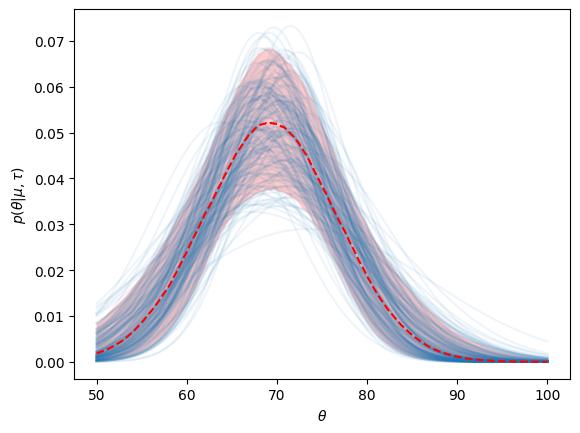

In [46]:
xvals = np.linspace(50, 100, num=1000)
n_draws = 1000
p_thetas = np.zeros((n_draws, xvals.size))
for ii in range(n_draws):
    idx = np.random.randint(0, num_samples)
    if ii % 5 == 0:
        plt.plot(xvals, np.exp(dist.Normal(samples['mu'][idx], 10**samples['logtau'][idx]).log_prob(xvals)),
            c='C0', alpha=0.075)
    p_thetas[ii] = np.exp(dist.Normal(samples['mu'][idx], 10**samples['logtau'][idx]).log_prob(xvals))
hyperprior_median, five, ninetyfive = np.percentile(p_thetas, [50, 5, 95], axis=0)    
plt.plot(xvals, hyperprior_median, c='r', ls='--')
plt.fill_between(xvals, five, ninetyfive, facecolor='r', alpha=0.2)
plt.xlabel("$\\theta$")
plt.ylabel("$p(\\theta | \\mu, \\tau)$")
plt.show()

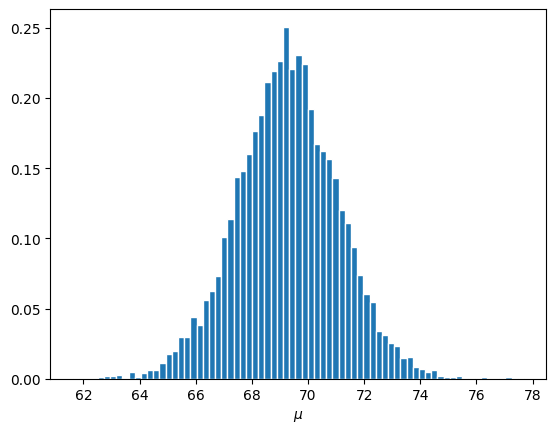

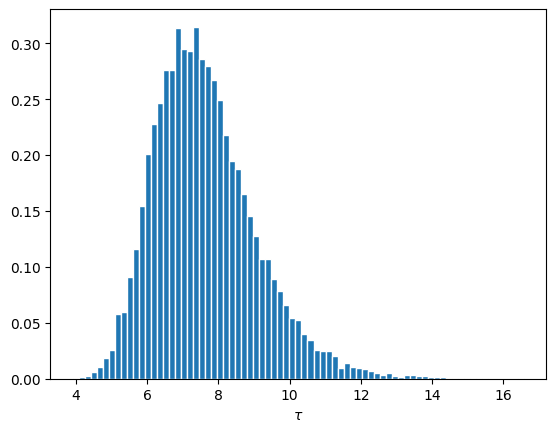

In [48]:
plt.hist(samples['mu'], density=True, bins='auto', edgecolor='w')
plt.xlabel("$\\mu$")
plt.show()
plt.hist(10**samples['logtau'], density=True, bins='auto', edgecolor='w')
plt.xlabel("$\\tau$")
plt.show()